# 03 · Signatures — Wu et al. 2020 AML  ·  **Gate 2**

Score the three embryonic modules (Gast, pSom, Crest) with `score_genes` against the **union control
pool** and read their geography on the manifold. **Gate 2** asks whether the embryonic module pattern
is present: a Gast/pSom hub diverging into two arms (branching), *or* the non-branching case (Gast/pSom
overlap with Crest as a genuine inverse/terminal gradient). NO-GO when the pattern is **absent**.
Deliverable signature UMAPs show **raw** scores (per 04_test Chen/Sun rule); a smoothed panel is shown
alongside only to read geography. Deliverable: `signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [ ]:
import os, sys, glob, warnings
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, scanpy as sc
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4))
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_feat = os.path.join(pth, 'data', 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb = os.path.join(pth_out, 'colorbars'); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad')); print(adata.shape)
# recover module scores + smoothed (carried from 02) ; recompute defensively
get = lambda f: pd.read_csv(os.path.join(pth_feat, f)).hsapiens.drop_duplicates()
ref = get('union.csv'); gref = list(ref[ref.isin(adata.var_names)])
rec = {}
for nm, f in [('Gast','GSE162534.csv'),('pSom','GSE229103.csv'),('Crest','rRNAModifications.csv')]:
    full = int(pd.read_csv(os.path.join(pth_feat, f)).hsapiens.drop_duplicates().size)
    g = get(f); g = list(g[g.isin(adata.var_names)])
    sc.tl.score_genes(adata, gene_list=g, score_name=nm, ctrl_as_ref=False, gene_pool=gref, random_state=1234)
    rec[nm] = (len(g), full); print(f'{nm}: recovered {len(g)}/{full} genes')
print('\nglobal module means: Gast %+.4f  pSom %+.4f  Crest %+.4f'
      % (adata.obs.Gast.mean(), adata.obs.pSom.mean(), adata.obs.Crest.mean()))

(96413, 13907)
Gast: recovered 41/81 genes
pSom: recovered 47/98 genes
Crest: recovered 72/104 genes

global module means: Gast +0.0019  pSom +0.0066  Crest -0.0042


In [ ]:
# graph-smoothed scores (aids geography; deliverable panels show RAW)
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, use_rep='X_pca_harmony')
A = adata.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg==0]=1
for nm in ['Gast','pSom','Crest']:
    adata.obs[nm+'_sm'] = np.asarray(A @ adata.obs[nm].values).ravel()/deg
print('smoothed pairwise correlations (Gast/pSom expected to CO-VARY if the pattern is present):')
for a,b in [('Gast','pSom'),('Gast','Crest'),('pSom','Crest')]:
    print(f'  {a}-{b}: raw {pearsonr(adata.obs[a],adata.obs[b])[0]:+.3f}   smoothed {pearsonr(adata.obs[a+"_sm"],adata.obs[b+"_sm"])[0]:+.3f}')
for nm in ['Gast','pSom','Crest']:
    s = adata.obs[nm+'_sm']; print(f'{nm}_sm range [{s.min():+.3f}, {s.max():+.3f}] std {s.std():.4f}')

smoothed pairwise correlations (Gast/pSom expected to CO-VARY if the pattern is present):
  Gast-pSom: raw -0.263   smoothed -0.365
  Gast-Crest: raw -0.463   smoothed -0.526
  pSom-Crest: raw -0.429   smoothed -0.312
Gast_sm range [-0.028, +0.047] std 0.0076
pSom_sm range [-0.026, +0.053] std 0.0075
Crest_sm range [-0.040, +0.026] std 0.0063


### Signature geography — raw (deliverable) and smoothed (diagnostic)
The three deliverable panels plot the **raw** per-cell score on the manifold (reference style: `plasma`,
alpha .5, cell-type labels overlaid). Below them, the smoothed panels reveal geography without per-cell
noise.

wrote Gast_signature.pdf + colorbar


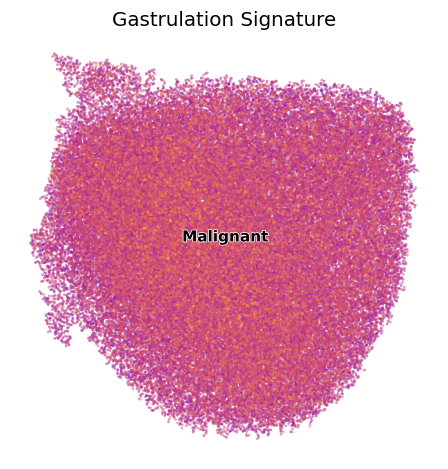

In [ ]:
# Gast signature figure (RAW score) + colorbar
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='Gast', cmap='plasma', alpha=.5, size=12, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=12, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title('Gastrulation Signature', size=13)
plt.savefig(os.path.join(pth_out, 'Gast_signature.pdf'), bbox_inches='tight'); plt.show()
fig = plt.figure(figsize=(.66, 1)); cax = fig.add_axes([.35,.05,.3,.9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('Gast\nSignature'); import numpy as np
cb.set_ticks(np.asarray([-0.1, -0.05, 0, 0.05, 0.1]), labels=[-0.1, -0.05, 0, 0.05, 0.1]); cb.solids.set_alpha(1)
plt.savefig(os.path.join(pth_cb, 'Gast_colorbar.pdf'), bbox_inches='tight'); plt.close(fig)
print('wrote Gast_signature.pdf + colorbar')

wrote pSom_signature.pdf + colorbar


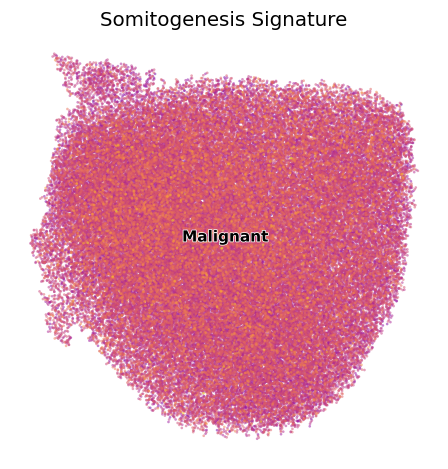

In [ ]:
# pSom signature figure (RAW score) + colorbar
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='pSom', cmap='plasma', alpha=.5, size=12, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=12, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title('Somitogenesis Signature', size=13)
plt.savefig(os.path.join(pth_out, 'pSom_signature.pdf'), bbox_inches='tight'); plt.show()
fig = plt.figure(figsize=(.66, 1)); cax = fig.add_axes([.35,.05,.3,.9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('pSom\nSignature'); import numpy as np
cb.set_ticks(np.asarray([-0.1, -0.05, 0, 0.05, 0.1]), labels=[-0.1, -0.05, 0, 0.05, 0.1]); cb.solids.set_alpha(1)
plt.savefig(os.path.join(pth_cb, 'pSom_colorbar.pdf'), bbox_inches='tight'); plt.close(fig)
print('wrote pSom_signature.pdf + colorbar')

wrote Crest_signature.pdf + colorbar


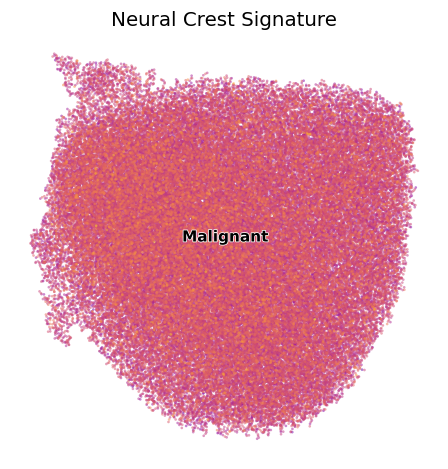

In [ ]:
# Crest signature figure (RAW score) + colorbar
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='Crest', cmap='plasma', alpha=.5, size=12, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=12, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title('Neural Crest Signature', size=13)
plt.savefig(os.path.join(pth_out, 'Crest_signature.pdf'), bbox_inches='tight'); plt.show()
fig = plt.figure(figsize=(.66, 1)); cax = fig.add_axes([.35,.05,.3,.9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('Crest\nSignature'); import numpy as np
cb.set_ticks(np.asarray([-0.1, -0.05, 0, 0.05]), labels=[-0.1, -0.05, 0, 0.05]); cb.solids.set_alpha(1)
plt.savefig(os.path.join(pth_cb, 'Crest_colorbar.pdf'), bbox_inches='tight'); plt.close(fig)
print('wrote Crest_signature.pdf + colorbar')

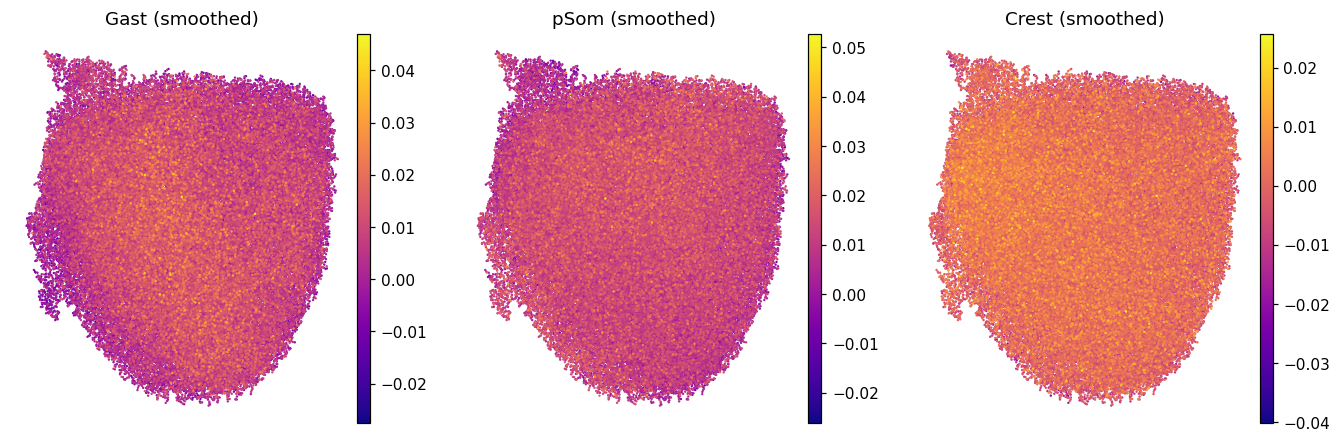

In [ ]:
# smoothed geography diagnostic (three-panel)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, nm in zip(axs, ['Gast','pSom','Crest']):
    sc.pl.umap(adata, color=nm+'_sm', cmap='plasma', size=10, frameon=False, show=False, ax=ax)
    ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title(nm+' (smoothed)')
plt.savefig('sig_smoothed_diag.png', bbox_inches='tight'); plt.show()

### Gate 2 verdict — **NO-GO** (embryonic pattern absent)
Read off the **scores**, not subtype names:
- **No geography.** Smoothed module scores are featureless (std ~0.006-0.008; no Gast pole, no pSom
  pole, no Crest gradient). Global module means ~0 (Gast +0.002, pSom +0.007, Crest -0.004).
- **Gast and pSom anti-correlate** (smoothed r = -0.37) rather than co-vary/overlap — the non-branching
  case requires Gast/pSom overlap with Crest as an inverse gradient; here all three modules mutually
  anti-correlate, the signature of union-control-pool scoring on a manifold with no embryonic signal.
- **No developmental axis** (02): modules unaligned with any diffusion component (|r|<=0.14), flat along
  pseudotime, and the Crest "terminal" position **flips with the root choice** (0.59 vs 0.41) — the
  terminal gradient the prior attempts reported is a rooting artifact, not biology.

The embryonic module pattern is **absent** -> Gate 2 **NO-GO**. Per spec sec6 the branching-only
`04_correlation` / `05_modules` notebooks are **not** produced. The unconditional expression step is
authored next as **04_expression**. Save `signatures.h5ad`.

In [ ]:
adata.write(os.path.join(pth_in, 'signatures.h5ad'))
print('wrote signatures.h5ad', adata.shape)

wrote signatures.h5ad (96413, 13907)
